# Curso: Data Mining — Semana 10 - Miércoles
## <font color=green>Laboratorio: DBSCAN y Clustering jerárquico</font>

**Docente:** Soledad Espezúa Llerena


## <font color=green>Objetivos</font>

- explicar cómo `eps` y `min_samples` modifican el resultado de DBSCAN;
- distinguir puntos **núcleo**, **frontera** y **ruido**;
- utilizar un gráfico de **k-distancias** como apoyo para proponer un valor inicial de `eps`;
- interpretar un **dendrograma** y reconocer el efecto del criterio de enlace;
- comparar cualitativamente K-means, DBSCAN y clustering jerárquico sin utilizar todavía métricas internas de evaluación.

> **Silhouette y Davies-Bouldin se trabajarán la próxima semana.**


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# <font color=blue>PARTE I. DBSCAN: clustering basado en densidad</font>

K-means funciona especialmente bien cuando los grupos son relativamente compactos alrededor de centroides.

Pero no todos los datos presentan esa forma.

En esta parte utilizaremos un conjunto de datos con **dos medias lunas**, donde la estructura natural de los grupos es curva.


## <font color=green>1. Generamos datos con formas no esféricas</font>

Utilizaremos `make_moons()` para crear dos estructuras curvas.

Aunque ambas variables ya están en escalas similares, aplicaremos `StandardScaler` para mantener una práctica consistente con métodos basados en distancia.


In [ ]:
# Generamos dos medias lunas con un poco de ruido.
# El segundo resultado de make_moons() contiene etiquetas artificiales,
# pero NO las utilizaremos para construir los clusters.

X_moons, _ = make_moons(
    n_samples=450,
    noise=0.07,
    random_state=42
)

# Estandarizamos las dos variables.
scaler_moons = StandardScaler()
X_moons_std = scaler_moons.fit_transform(X_moons)

# Creamos un DataFrame solo para facilitar las visualizaciones.
moons = pd.DataFrame(
    X_moons_std,
    columns=["x1", "x2"]
)

display(moons.head())


In [ ]:
# Visualizamos los datos sin ninguna etiqueta de cluster.

ax = sns.scatterplot(
    data=moons,
    x="x1",
    y="x2",
    s=35
)

ax.set(
    title="Datos sin etiquetas",
    xlabel="x1",
    ylabel="x2"
)

plt.show()


## <font color=green>2. Recordatorio: ¿qué hace K-means en este caso?</font>

K-means asigna cada observación al centroide más cercano.

Por ello, tiende a generar regiones relativamente compactas alrededor de centroides y puede cortar de forma poco natural estructuras curvas.


In [ ]:
# Aplicamos K-means con K=2.
# Este resultado solo sirve como contraste con DBSCAN.

kmeans = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels_km = kmeans.fit_predict(X_moons_std)

# Convertimos las etiquetas a categoría para usarlas como grupos visuales.
viz_km = moons.copy()
viz_km["cluster"] = pd.Series(labels_km).astype("category")

ax = sns.scatterplot(
    data=viz_km,
    x="x1",
    y="x2",
    hue="cluster",
    s=35
)

ax.set(
    title="K-means sobre una estructura no esférica",
    xlabel="x1",
    ylabel="x2"
)

plt.show()


## <font color=green>3. Parámetros principales de DBSCAN</font>

DBSCAN forma clusters conectando regiones de alta densidad.

Los parámetros principales son:

- `eps`: radio máximo para considerar dos puntos como vecinos;
- `min_samples`: número mínimo de puntos dentro de la vecindad para que un punto sea **núcleo**;
- `metric`: medida de distancia utilizada.

En scikit-learn, DBSCAN utiliza distancia euclidiana por defecto.

> `eps` se interpreta en el espacio **después del preprocesamiento**.  
> Si cambia el escalamiento, también cambia el significado de `eps`.


## <font color=green>4. Una ayuda para proponer `eps`: gráfico de k-distancias</font>

No existe un valor universal de `eps`.

Una heurística útil consiste en:

1. fijar `min_samples`;
2. calcular para cada observación la distancia a su vecino número `min_samples`;
3. ordenar esas distancias;
4. buscar una zona donde la curva comience a crecer con mayor rapidez.

Ese cambio de pendiente puede servir como **valor inicial** de `eps`, no como una regla automática.


In [ ]:
# DBSCAN considerará núcleo a un punto si encuentra
# al menos 5 observaciones en su vecindad, incluido él mismo.
min_samples = 5

# Buscamos, para cada punto, sus 5 vecinos más próximos.
vecinos = NearestNeighbors(
    n_neighbors=min_samples
)

vecinos.fit(X_moons_std)

# Obtenemos las distancias a esos vecinos.
distancias, _ = vecinos.kneighbors(X_moons_std)

# Para cada punto tomamos la distancia al último vecino considerado.
# Esta distancia indica el radio necesario para reunir min_samples puntos.
k_distancias = distancias[:, -1]

# Ordenamos esas distancias para construir el gráfico de k-distancias.
k_distancias = np.sort(k_distancias)
kdist_df = pd.DataFrame({
    "observacion_ordenada": np.arange(len(k_distancias)),
    "k_distancia": k_distancias
})

display(kdist_df.tail())

In [ ]:
# Graficamos las k-distancias ordenadas.

ax = sns.lineplot(
    data=kdist_df,
    x="observacion_ordenada",
    y="k_distancia"
)

ax.set(
    title=f"Gráfico de {min_samples}-distancias",
    xlabel="Observaciones ordenadas",
    ylabel=f"Distancia al vecino {min_samples}"
)

plt.show()


### Interpretación

En este ejemplo, un valor alrededor de `eps = 0.17 a 0.25` es un punto de partida razonable.

Luego debemos revisar:

- cuántos clusters se forman;
- cuánto ruido aparece;
- si pequeñas variaciones de `eps` cambian completamente el resultado.


## <font color=green>5. Aplicamos DBSCAN</font>


In [ ]:
# Valor inicial propuesto a partir del gráfico de 5-distancias.
eps_elegido = 0.25

# Aplicamos DBSCAN con ese valor inicial.
dbscan = DBSCAN(
    eps=eps_elegido, # radio máximo para considerar vecinos
    min_samples=5    # mínimo de puntos para formar una zona densa
)

# Ajustamos DBSCAN y obtenemos la etiqueta de cada observación.
# Las etiquetas 0, 1, 2, ... representan clusters.
# La etiqueta -1 representa ruido.
labels_db = dbscan.fit_predict(X_moons_std)

# Creamos una copia de los datos para facilitar la visualización.
viz_db = moons.copy()

# Convertimos las etiquetas a categóricas porque representan grupos,
# no valores numéricos ordenados.
viz_db["cluster"] = pd.Series(labels_db).astype("category")

# Graficamos cada observación coloreada según el cluster encontrado.
ax = sns.scatterplot(
    data=viz_db,
    x="x1",
    y="x2",
    hue="cluster",
    s=35
)

ax.set(
    title=f"DBSCAN — eps={eps_elegido}, min_samples={min_samples}",
    xlabel="x1",
    ylabel="x2"
)

plt.show()

In [ ]:
# Resumimos el resultado de DBSCAN.

# La etiqueta -1 corresponde a ruido y no se cuenta como cluster.
etiquetas_unicas = set(labels_db)

# Cuenta cuántos clusters encontró DBSCAN, pero sin contar el ruido.
n_clusters_db = len(etiquetas_unicas) - (1 if -1 in etiquetas_unicas else 0)

# Porcentaje de observaciones etiquetadas como ruido.
porcentaje_ruido = np.mean(labels_db == -1) * 100

# Número de observaciones por etiqueta.
conteos_db = (
    pd.Series(labels_db, name="cluster")
    .value_counts()
    .sort_index()
)

print("Número de clusters:", n_clusters_db)
print("Porcentaje de ruido:", round(porcentaje_ruido, 1), "%")
print("\nTamaño por etiqueta:")
display(conteos_db.to_frame("n"))

## <font color=green>6. Sensibilidad de DBSCAN a `eps`</font>

DBSCAN no requiere que indiquemos el número de clusters, pero sí puede cambiar bastante cuando modificamos `eps`.

Compararemos varios radios manteniendo fijo `min_samples`.


In [ ]:
# Probamos valores cercanos al `eps` propuesto
# para verificar si la solución es estable.

# No estamos buscando todavía una "métrica óptima";
# observamos cómo cambia la estructura encontrada.

comparacion_eps = []

for eps in [0.17, 0.20, 0.25]:

    modelo = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = modelo.fit_predict(X_moons_std)

    # Número de clusters, sin contar el ruido (-1).
    etiquetas = set(labels)

    # Cuenta cuántos clusters encontró DBSCAN, pero sin contar el ruido.
    n_clusters = len(etiquetas) - (1 if -1 in etiquetas else 0)

    # Porcentaje de observaciones identificadas como ruido.
    porcentaje_ruido = np.mean(labels == -1) * 100

    comparacion_eps.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "ruido_%": porcentaje_ruido
    })

comparacion_eps = pd.DataFrame(comparacion_eps)

display(comparacion_eps.round(2))

In [ ]:
# Visualizamos cómo cambia DBSCAN con distintos valores de eps.

for eps in [0.17, 0.20, 0.25]:

    modelo = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = modelo.fit_predict(X_moons_std)

    viz = moons.copy()
    viz["cluster"] = pd.Series(labels).astype("category")

    plt.figure(figsize=(6, 4))

    ax = sns.scatterplot(
        data=viz,
        x="x1",
        y="x2",
        hue="cluster",
        s=35
    )

    ax.set(
        title=f"DBSCAN — eps={eps}",
        xlabel="x1",
        ylabel="x2"
    )

    plt.show()

# <font color=blue>PARTE II. Clustering jerárquico aglomerativo</font>

El clustering jerárquico aglomerativo comienza considerando:

cada observación = un cluster

y va realizando **fusiones sucesivas** hasta construir una jerarquía.


> **¿Cómo medimos la distancia entre dos clusters?**

La respuesta depende del **criterio de enlace** (`linkage`).


## <font color=green>7. Creamos un conjunto sencillo para estudiar el dendrograma</font>

Usaremos un conjunto sintético de 45 observaciones y dos variables.

No utilizaremos ninguna clase conocida para construir los grupos.


In [ ]:
# Creamos datos con tres zonas relativamente compactas.
# La segunda salida contiene etiquetas artificiales de generación,
# pero no las utilizaremos.

X_hier, _ = make_blobs(
    n_samples=45,
    centers=3,
    cluster_std=[0.60, 0.70, 0.55],
    random_state=12
)

# Estandarizamos porque el clustering jerárquico también
# depende de las distancias entre observaciones.
scaler_hier = StandardScaler()
X_hier_std = scaler_hier.fit_transform(X_hier)

hier_df = pd.DataFrame(
    X_hier_std,
    columns=["x1", "x2"]
)

ax = sns.scatterplot(
    data=hier_df,
    x="x1",
    y="x2",
    s=55
)

ax.set(
    title="Datos para clustering jerárquico",
    xlabel="x1",
    ylabel="x2"
)

plt.show()


## <font color=green>8. Construimos el dendrograma con Ward</font>

`Ward` fusiona los dos grupos cuya unión produce el menor incremento de la variación interna.

Ward se utiliza con distancia euclidiana.


In [ ]:
# 1. Construimos el dendrograma para explorar la jerarquía.
# Cada fila de Z describe una fusión realizada por el algoritmo.

Z_ward = linkage(
    X_hier_std,
    method="ward"
)

print("Dimensión de la matriz de enlace:", Z_ward.shape)

# Mostramos las primeras fusiones.
Z_ward_df = pd.DataFrame(
    Z_ward,
    columns=[
        "grupo_1",
        "grupo_2",
        "distancia_fusion",
        "n_observaciones"
    ]
)

display(Z_ward_df.head())


In [ ]:
# Dibujamos el dendrograma completo.

plt.figure(figsize=(12, 5))

dendrogram(
    Z_ward,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Dendrograma aglomerativo — Ward")
plt.xlabel("Observaciones")
plt.ylabel("Distancia de fusión")

plt.show()


### ¿Cómo leer el dendrograma?

- Cada hoja representa una observación.
- Las ramas muestran qué observaciones o grupos se fusionan.
- La altura de una unión representa la **distancia de fusión**.
- Un corte horizontal define una posible partición.
- Un salto vertical grande puede sugerir que las fusiones superiores están uniendo grupos relativamente diferentes.

> El dendrograma no entrega automáticamente un único número “correcto” de clusters.


## <font color=green>9. Obtenemos una partición a partir del árbol</font>

Un forma de obtener los grupos es cortar el árbol y solicitar por ejemplo obtener **3 grupos**.

In [ ]:
# 2. Aplicamos clustering jerárquico con 3 grupos.


# fcluster permite extraer etiquetas desde el dendrograma.
labels_hier = fcluster(
    Z_ward, # Z_ward contiene toda la jerarquía de fusiones construida previamente.
    t=3, # indica que queremos obtener como máximo 3 clusters
    criterion="maxclust" # solicita una partición con hasta 3 clusters.
)

# Restamos 1 únicamente para que las etiquetas queden 0, 1 y 2.
labels_hier = labels_hier - 1

viz_hier = hier_df.copy()
viz_hier["cluster"] = pd.Series(labels_hier).astype("category")

ax = sns.scatterplot(
    data=viz_hier,
    x="x1",
    y="x2",
    hue="cluster",
    s=60
)

ax.set(
    title="Partición obtenida del dendrograma — Ward",
    xlabel="x1",
    ylabel="x2"
)

plt.show()


Otra forma es observando el dendrograma, proponemos un corte
horizontal a una distancia de fusión igual a 2.

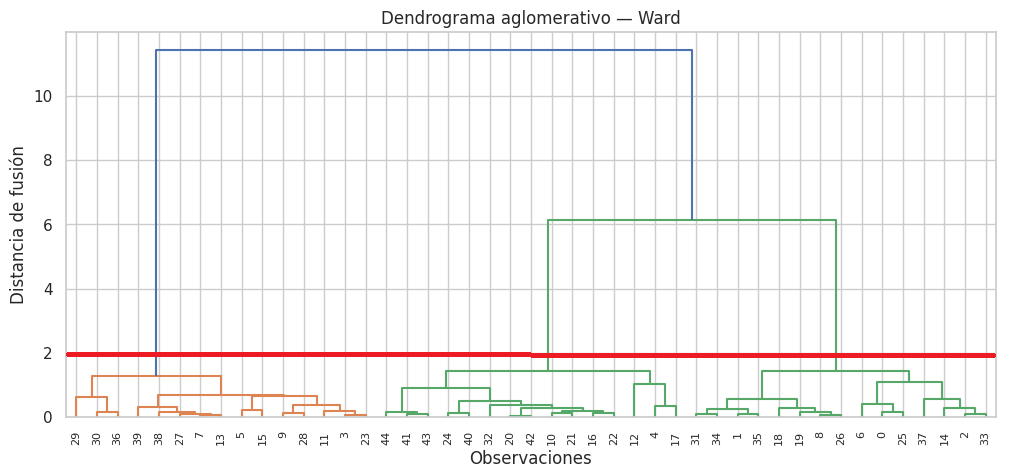

In [ ]:
# Proponemos un corte horizontal a una distancia de fusión igual a 2.

altura_corte = 2

labels_hier = fcluster(
    Z_ward,
    t=altura_corte,
    criterion="distance"
)

# fcluster comienza las etiquetas en 1.
# Las convertimos a 0, 1, 2, ...
labels_hier = labels_hier - 1

In [ ]:
# Revisamos el tamaño de los grupos obtenidos.

tamanos_hier = (
    pd.Series(labels_hier, name="cluster")
    .value_counts()
    .sort_index()
)

display(
    tamanos_hier.to_frame("n")
)


## <font color=green>10. ¿Qué cambia al modificar el criterio de enlace?</font>

Compararemos:

- `single`: utiliza la menor distancia entre puntos de dos clusters;
- `complete`: utiliza la mayor distancia;
- `average`: utiliza la distancia promedio;
- `ward`: minimiza el incremento de la variación interna.

Usaremos el mismo número de clusters para observar solamente el efecto del enlace.


In [ ]:
# Guardamos la solución de cada criterio de enlace.

resultados_linkage = {}

for metodo in [
    "single",
    "complete",
    "average",
    "ward"
]:

    modelo_h = AgglomerativeClustering(
        n_clusters=3,
        linkage=metodo
    )

    resultados_linkage[metodo] = (
        modelo_h.fit_predict(X_hier_std)
    )

# Construimos una tabla para observar las primeras etiquetas.
comparacion_linkage = pd.DataFrame(
    resultados_linkage
)

display(comparacion_linkage.head(12))


In [ ]:
# Comparamos el tamaño de los clusters producidos por cada enlace.

resumen_linkage = []

for metodo, etiquetas in resultados_linkage.items():

    conteos = pd.Series(etiquetas).value_counts()

    resumen_linkage.append({
        "linkage": metodo,
        "n_clusters": len(conteos),
        "tamaño_min": conteos.min(), #tamaño del cluster más pequeño
        "tamaño_max": conteos.max()  #tamaño del cluster más grande
    })

resumen_linkage = pd.DataFrame(resumen_linkage)

display(resumen_linkage)


In [ ]:
# Visualizamos cada criterio por separado.
# Cada gráfico utiliza exactamente los mismos datos;
# solo cambia el criterio de enlace.

for metodo, etiquetas in resultados_linkage.items():

    viz = hier_df.copy()
    viz["cluster"] = pd.Series(
        etiquetas
    ).astype("category")

    plt.figure(figsize=(6, 4))

    ax = sns.scatterplot(
        data=viz,
        x="x1",
        y="x2",
        hue="cluster",
        s=55
    )

    ax.set(
        title=f"Clustering aglomerativo — linkage={metodo}",
        xlabel="x1",
        ylabel="x2"
    )

    plt.show()


## <font color=green>Observaciones</font>

- Los distintos criterios de enlace **no tienen por qué producir exactamente la misma partición**. Cada uno define de manera diferente qué significa que dos clusters estén próximos.

- **Ward** tiende a generar grupos compactos porque fusiona los clusters cuya unión produce el menor incremento de la variación interna.

- **Complete linkage** también suele favorecer grupos relativamente compactos, porque considera la mayor distancia entre los puntos de dos clusters antes de unirlos.

- **Average linkage** utiliza la distancia promedio entre los puntos de ambos clusters, por lo que suele representar una alternativa intermedia entre `single` y `complete`.

- **Single linkage** utiliza la distancia entre los dos puntos más cercanos de cada cluster. Por ello puede aparecer el efecto de **encadenamiento**: grupos distintos pueden terminar unidos mediante una sucesión de puntos cercanos.

- El criterio de enlace forma parte de la definición del clustering porque determina **qué clusters se consideran más próximos y, por tanto, en qué orden se realizan las fusiones**.

> No existe un criterio de enlace universalmente mejor. La elección depende de la estructura de los datos y del tipo de grupos que se busca identificar.


###<font color=red>**Alternativa:**</font>
Usando directamente `AgglomerativeClustering` de scikit-learn, en lugar de construir primero `Z_ward` con SciPy y luego usar `fcluster()`.

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Construimos el modelo de clustering jerárquico aglomerativo.
modelo_hier = AgglomerativeClustering(
    n_clusters=3, # indica que queremos obtener 3 grupos.
    linkage="ward" # "ward" fusiona los grupos buscando el menor
                   # incremento posible de la variación interna.
)

# Ajustamos el modelo y obtenemos directamente
# la etiqueta de cluster de cada observación.
labels_hier = modelo_hier.fit_predict(X_hier_std)

# Creamos un DataFrame para facilitar la visualización con Seaborn.
viz_hier = pd.DataFrame(
    X_hier_std,
    columns=["x1", "x2"]
)

# Las etiquetas representan categorías, no valores numéricos.
viz_hier["cluster"] = pd.Series(labels_hier).astype("category")

# Visualizamos los clusters encontrados.
ax = sns.scatterplot(
    data=viz_hier,
    x="x1",
    y="x2",
    hue="cluster",
    s=60
)

ax.set(
    title="Clustering jerárquico aglomerativo — Ward",
    xlabel="x1",
    ylabel="x2"
)

plt.show()

# <font color=blue>PARTE III. ¿Qué algoritmo conviene?</font>

| Método | Idea principal | Fortalezas | Limitaciones típicas |
|---|---|---|---|
| **K-means** | cercanía a centroides | rápido; centroides interpretables | requiere \(K\); favorece grupos compactos; todos los puntos reciben cluster |
| **Jerárquico** | fusiones sucesivas | dendrograma; permite explorar varios niveles | mayor costo; las fusiones realizadas no se revierten |
| **DBSCAN** | conectividad por densidad | formas no esféricas; identifica ruido; no requiere \(K\) | sensible a `eps` y `min_samples`; difícil con densidades muy diferentes |

> **No existe un algoritmo universalmente mejor.**  
> La elección depende de la estructura de los datos, la noción de proximidad y el objetivo del análisis.


## <font color=green>11. Importante</font>

1. DBSCAN no necesita \(K\), pero sí requiere decisiones sobre densidad.
2. `eps` depende directamente del espacio y del escalamiento de los datos.
3. Un punto de ruido (`-1`) no es automáticamente un error de calidad.
4. En clustering jerárquico, el dendrograma representa una **jerarquía de fusiones**.
5. El criterio de enlace puede cambiar la partición obtenida.
6. Todavía no estamos evaluando cuál solución es “mejor” con métricas internas; eso se hará en la próxima sesión.


# <font color=blue>DESAFÍO GRUPAL — Comparar alternativas en su proyecto</font>

Retomen la **misma matriz analítica y la misma representación preparada para distancias** que utilizaron en K-means.

> No utilicen `cluster_kmeans` como atributo de entrada.  
> Esa columna es un **resultado** que servirá posteriormente para comparar soluciones.

## <font color=green>A. DBSCAN</font>

1. Trabajen con su matriz escalada.
2. Propongan un valor inicial de `min_samples`.
3. Construyan el gráfico de **k-distancias**.
4. Propongan un valor inicial de `eps`.
5. Prueben al menos **tres valores cercanos de `eps`**.
6. Reporten:
   - número de clusters;
   - porcentaje de ruido;
   - tamaño de cada grupo.
7. Guarden las etiquetas como:

```python
df_resultados["cluster_dbscan"] = labels_dbscan
```

## <font color=green>B. Clustering jerárquico</font>

8. Construyan un dendrograma con **Ward**.
9. Si el dataset es demasiado grande para visualizar el árbol completo, utilicen una **muestra reproducible solo para explorar el dendrograma**.
10. Prueben al menos otro criterio de enlace (`complete`, `average` o `single`).
11. Propongan una partición final y guarden:

```python
df_resultados["cluster_hier"] = labels_hier
```


### Conclusión grupal — máximo 8 líneas

Respondan:

- ¿Qué diferencias importantes observan entre las tres soluciones?
- ¿Algún método parece inadecuado para la estructura de sus datos? ¿Por qué?
- ¿Qué decisión de preprocesamiento o parámetros parece influir más?

> **No es obligatorio que los tres métodos produzcan una buena solución.**  
> La próxima semana utilizaremos Silhouette, Davies-Bouldin y perfilamiento para evaluar e interpretar con mayor rigor los resultados.

**Guarden las tres etiquetas:** `cluster_kmeans`, `cluster_dbscan` y `cluster_hier`.
